In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Загрузка данных
df = pd.read_csv('wine_quality_merged.csv')

# Первичный осмотр
print("Размерность:", df.shape)
print("Количество строк:", df.shape[0], "| Количество столбцов:", df.shape[1])
print()
print("Типы данных:")
print(df.dtypes)
print()
print('Первые пять строк:')
display(df.head())
print('Последние пять строк:')
display(df.tail())

Размерность: (6497, 13)
Количество строк: 6497 | Количество столбцов: 13

Типы данных:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
type                        str
dtype: object

Первые пять строк:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Последние пять строк:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white
6496,6.0,0.21,0.38,0.8,0.020,22.0,98.0,0.98941,3.26,0.32,11.8,6,white


In [3]:
print("Пропуски по столбцам:")
print(df.isnull().sum())
print()
print("Всего пропусков:", df.isnull().sum().sum())
print()
print("Количество дубликатов:", df.duplicated().sum())
print()
print("Дубликаты:")
display(df[df.duplicated()])

Пропуски по столбцам:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64

Всего пропусков: 0

Количество дубликатов: 1177

Дубликаты:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.99780,3.51,0.56,9.400000,5,red
11,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.99780,3.35,0.80,10.500000,5,red
27,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.99660,3.17,0.91,9.500000,5,red
40,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.99780,3.33,0.83,10.500000,5,red
65,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.99620,3.41,0.39,10.900000,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6427,6.4,0.230,0.35,10.30,0.042,54.0,140.0,0.99670,3.23,0.47,9.200000,5,white
6449,7.0,0.360,0.35,2.50,0.048,67.0,161.0,0.99146,3.05,0.56,11.100000,6,white
6450,6.4,0.330,0.44,8.90,0.055,52.0,164.0,0.99488,3.10,0.48,9.600000,5,white
6455,7.1,0.230,0.39,13.70,0.058,26.0,172.0,0.99755,2.90,0.46,9.000000,6,white


In [4]:
for col in df.columns:
    print(f"{col}: тип = {df[col].dtype}, "
          f"уникальных значений = {df[col].nunique()}")

print()
print("Классы в 'type':")
print(df['type'].value_counts())

fixed acidity: тип = float64, уникальных значений = 106
volatile acidity: тип = float64, уникальных значений = 187
citric acid: тип = float64, уникальных значений = 89
residual sugar: тип = float64, уникальных значений = 316
chlorides: тип = float64, уникальных значений = 214
free sulfur dioxide: тип = float64, уникальных значений = 135
total sulfur dioxide: тип = float64, уникальных значений = 276
density: тип = float64, уникальных значений = 998
pH: тип = float64, уникальных значений = 108
sulphates: тип = float64, уникальных значений = 111
alcohol: тип = float64, уникальных значений = 111
quality: тип = int64, уникальных значений = 7
type: тип = str, уникальных значений = 2

Классы в 'type':
type
white    4898
red      1599
Name: count, dtype: int64


In [31]:
# Анализ корректности вычисления среднего для каждого признака
analysis = pd.DataFrame({
    'Среднее': df[features].mean(),
    'Медиана': df[features].median(),
    'Мода': df[features].mode().iloc[0],
    'Ст. откл.': df[features].std(ddof=1),
    'Асимметрия': df[features].skew(),
    'Эксцесс': df[features].kurt(),
})

# абсолютное и относительное расхождение среднего и медианы
analysis['|Среднее − Медиана|'] = (analysis['Среднее'] - analysis['Медиана']).abs()
analysis['Расхождение, %'] = (
    analysis['|Среднее − Медиана|'] / analysis['Медиана'].abs() * 100
)

# коэффициент вариации
analysis['CV, %'] = analysis['Ст. откл.'] / analysis['Среднее'] * 100

# оценка корректности среднего
def judge(row):
    if row['Расхождение, %'] < 5 and abs(row['Асимметрия']) < 0.5:
        return 'Среднее корректно (симметричное распределение)'
    elif row['Расхождение, %'] < 15 and abs(row['Асимметрия']) < 1:
        return 'Среднее приемлемо, есть умеренная асимметрия'
    else:
        return 'Среднее смещено (асимметрия / влияние выбросов)'

analysis['Вывод'] = analysis.apply(judge, axis=1)

display(analysis.round(3))

,Среднее,Медиана,Мода,Ст. откл.,Асимметрия,Эксцесс,|Среднее − Медиана|,"Расхождение, %","CV, %",Вывод
fixed acidity,7.215,7.000,6.800,1.296,1.723,5.061,0.215,3.076,17.968,Среднее смещено (асимметрия / влияние выбросов)
volatile acidity,0.340,0.290,0.280,0.165,1.495,2.825,0.050,17.126,48.470,Среднее смещено (асимметрия / влияние выбросов)
citric acid,0.319,0.310,0.300,0.145,0.472,2.397,0.009,2.785,45.607,Среднее корректно (симметричное распределение)
residual sugar,5.443,3.000,2.000,4.758,1.435,4.359,2.443,81.441,87.408,Среднее смещено (асимметрия / влияние выбросов)
chlorides,0.056,0.047,0.044,0.035,5.400,50.898,0.009,19.221,62.522,Среднее смещено (асимметрия / влияние выбросов)
free sulfur dioxide,30.525,29.000,29.000,17.749,1.220,7.906,1.525,5.260,58.146,Среднее смещено (асимметрия / влияние выбросов)
total sulfur dioxide,115.745,118.000,111.000,56.522,-0.001,-0.372,2.255,1.911,48.833,Среднее корректно (симметричное распределение)
density,0.995,0.995,0.997,0.003,0.504,6.606,0.000,0.019,0.301,"Среднее приемлемо, есть умеренная асимметрия"
pH,3.219,3.210,3.160,0.161,0.387,0.368,0.009,0.265,4.996,Среднее корректно (симметричное распределение)
sulphates,0.531,0.510,0.500,0.149,1.797,8.654,0.021,4.170,28.010,Среднее смещено (асимметрия / влияние выбросов)


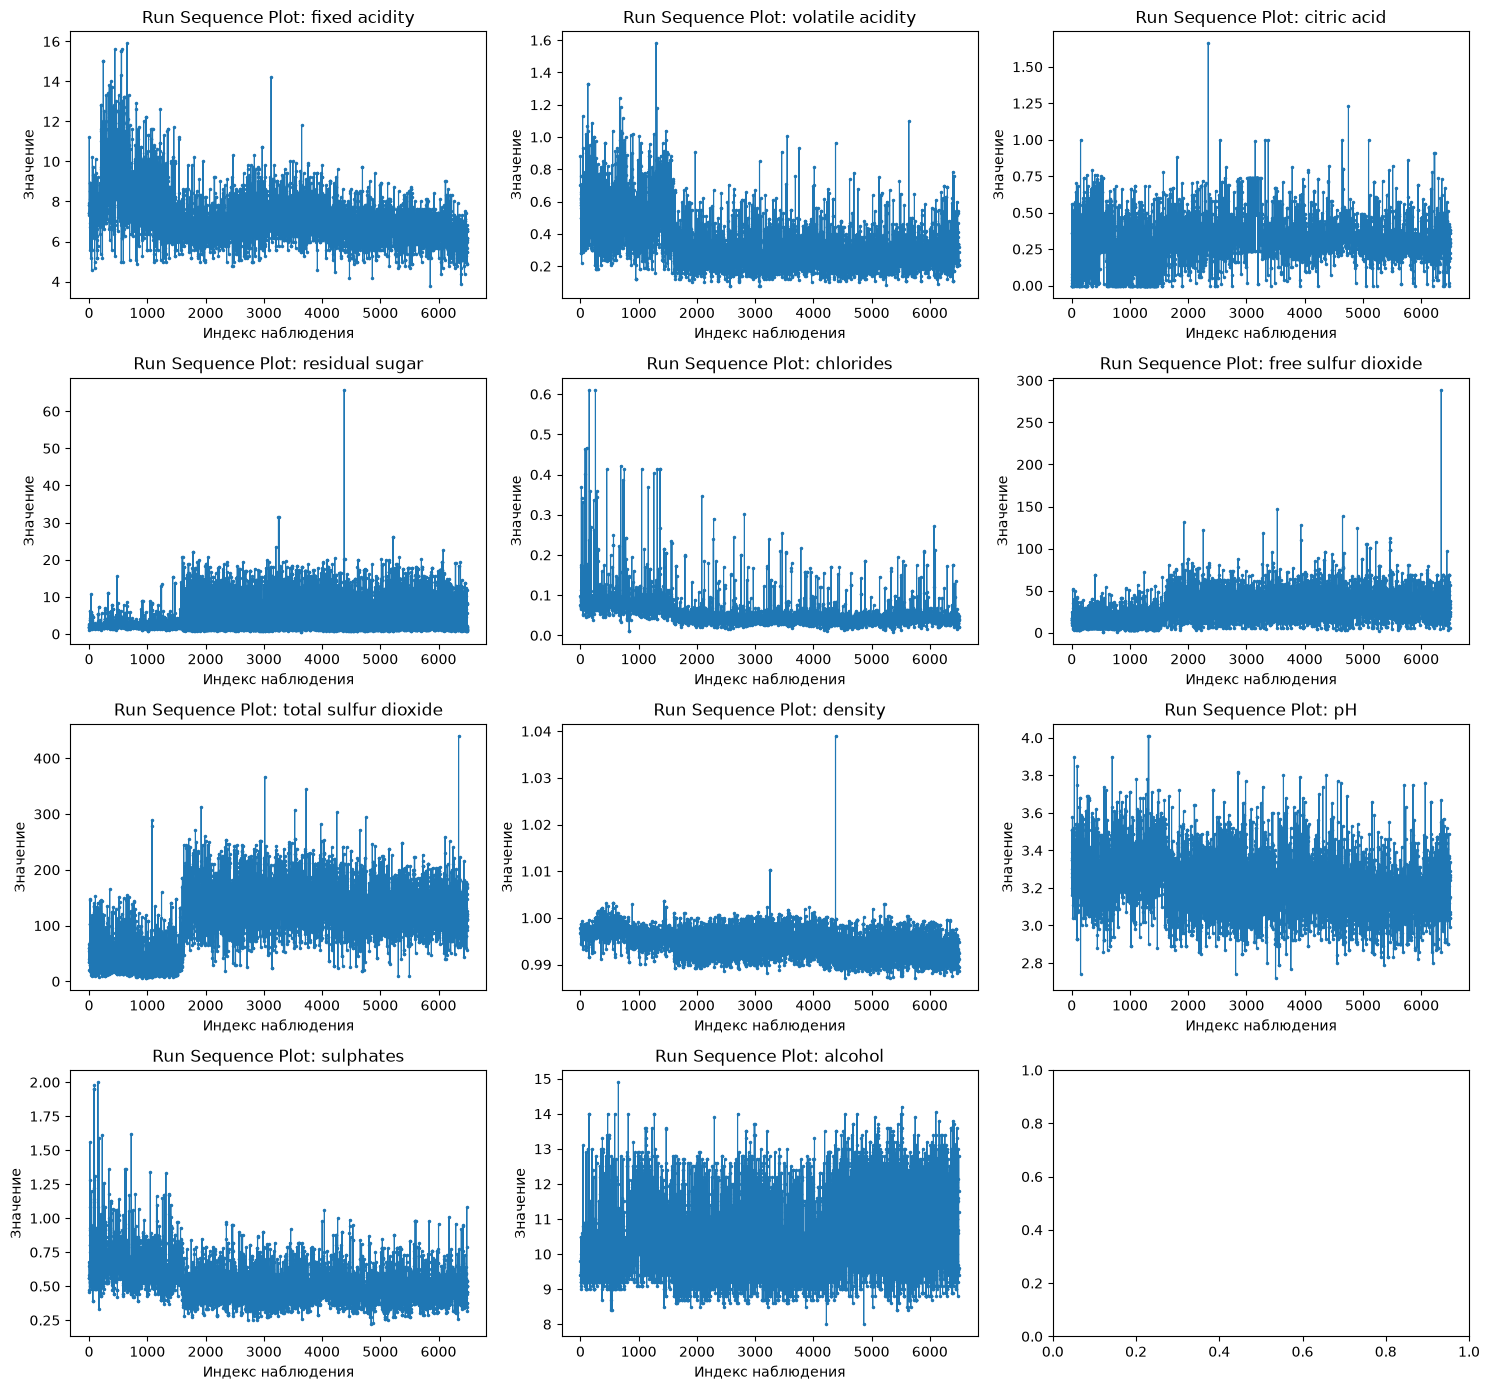

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    ax = axes[i]
    ax.plot(df[col], marker='.', markersize=3, linewidth=0.8)
    ax.set_title(f'Run Sequence Plot: {col}')
    ax.set_xlabel('Индекс наблюдения')
    ax.set_ylabel('Значение')
plt.tight_layout()
plt.show()

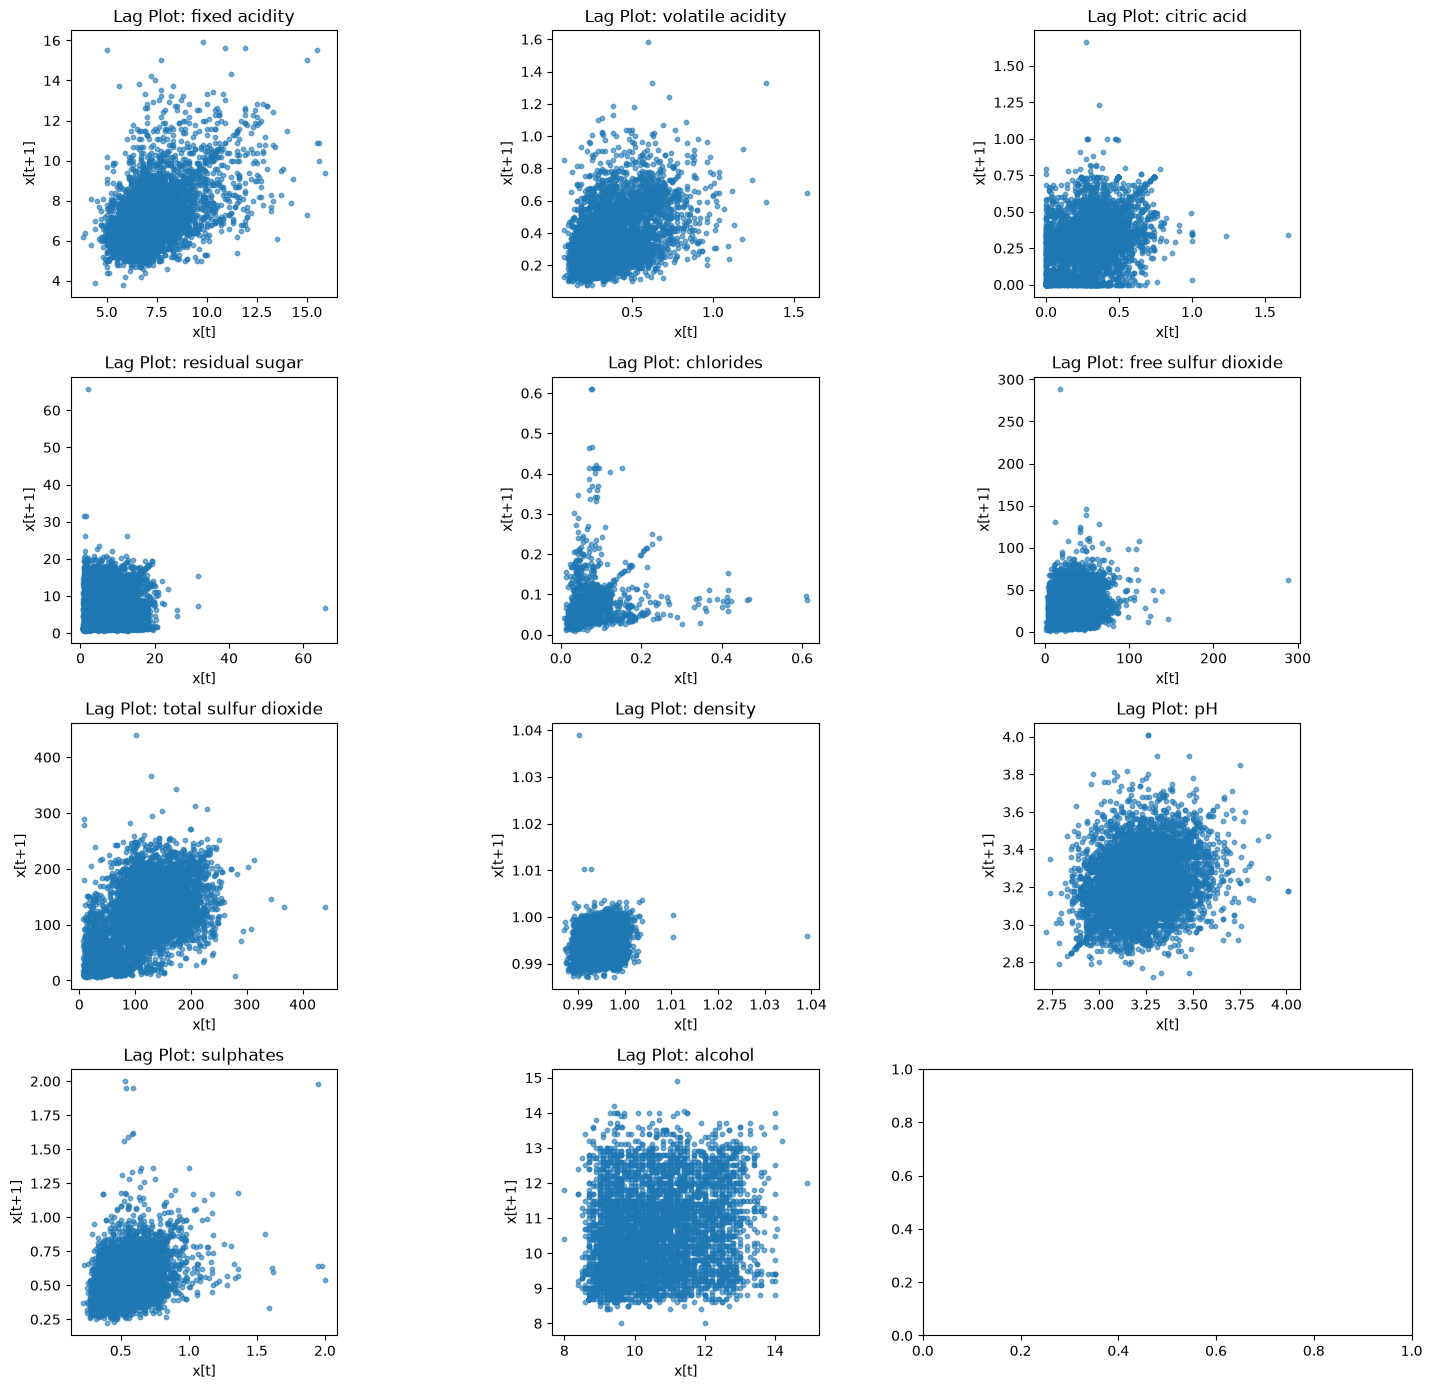

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    ax = axes[i]
    ax.scatter(df[col][:-1], df[col][1:], s=10, alpha=0.6)
    ax.set_title(f'Lag Plot: {col}')
    ax.set_xlabel('x[t]')
    ax.set_ylabel('x[t+1]')
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

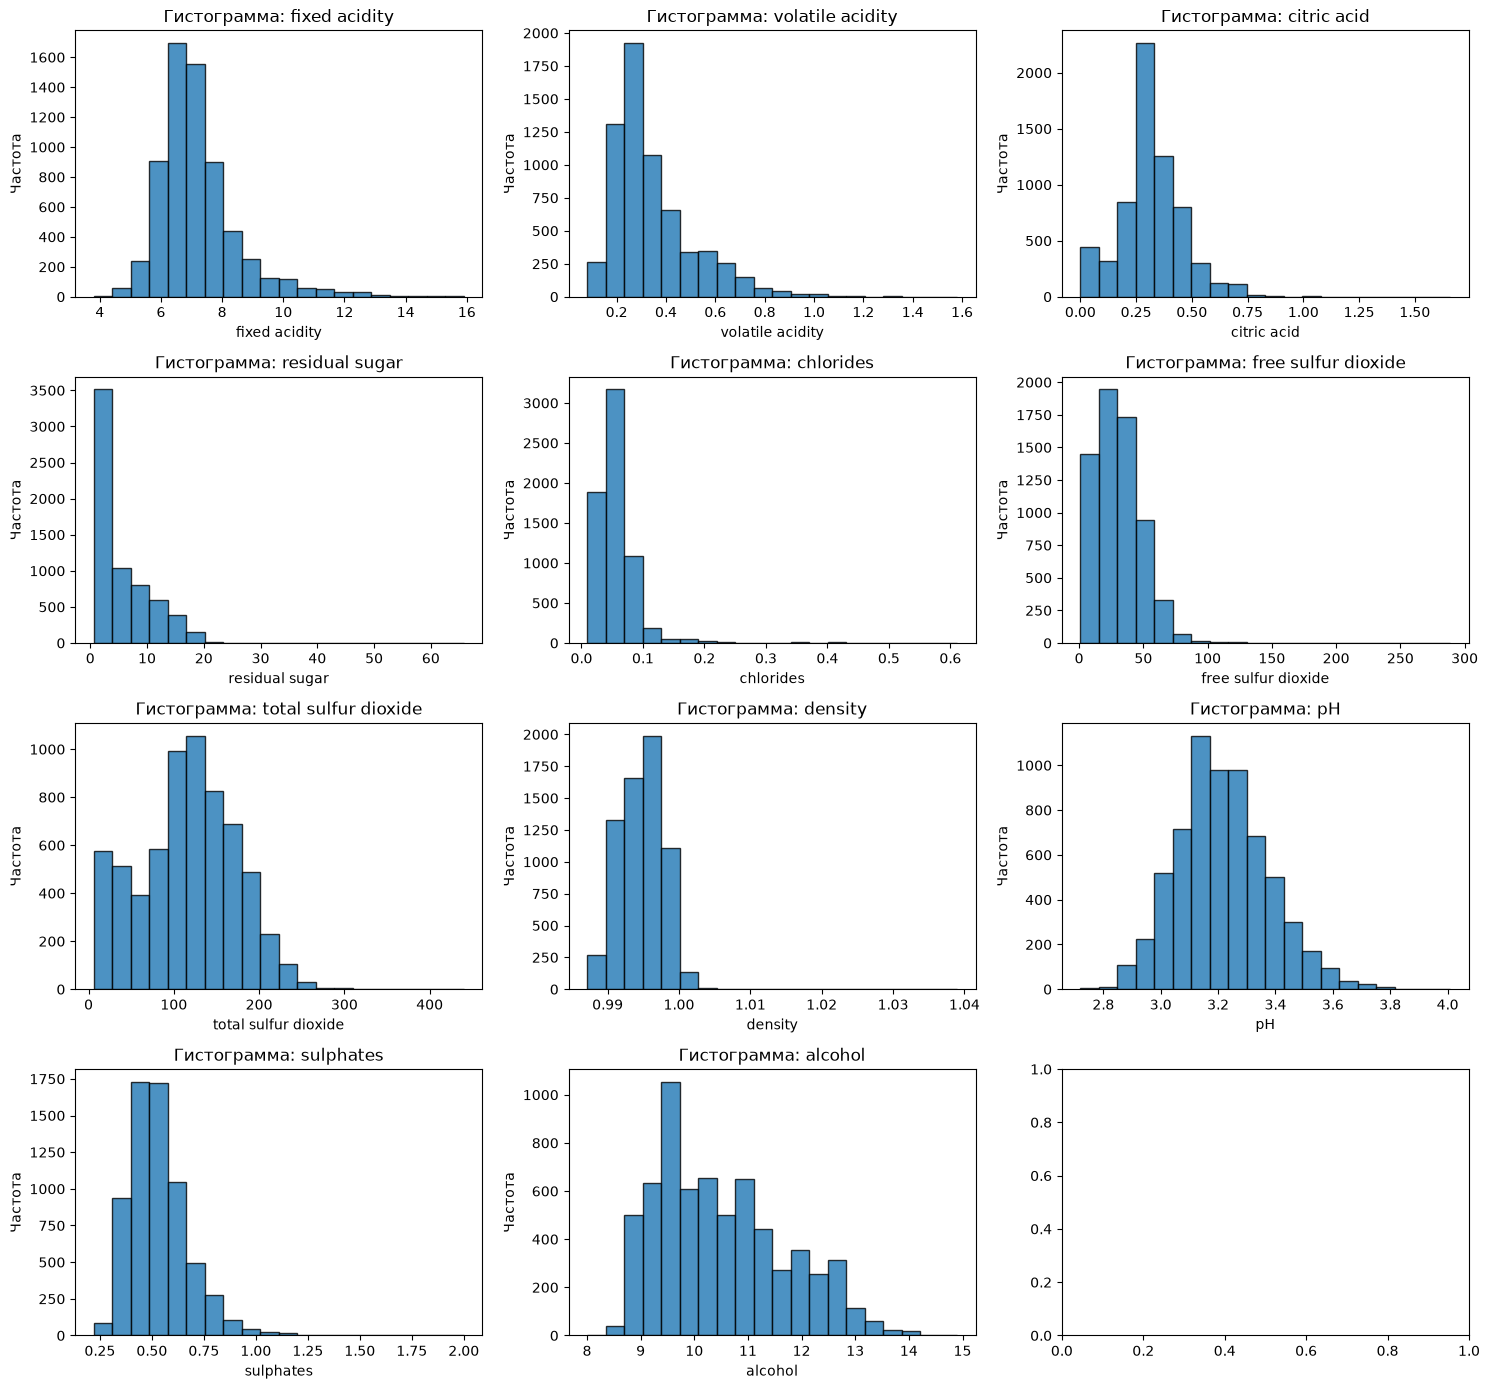

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    ax = axes[i]
    ax.hist(df[col], bins=20, edgecolor='black', alpha=0.8)
    ax.set_title(f'Гистограмма: {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Частота')
plt.tight_layout()
plt.show()

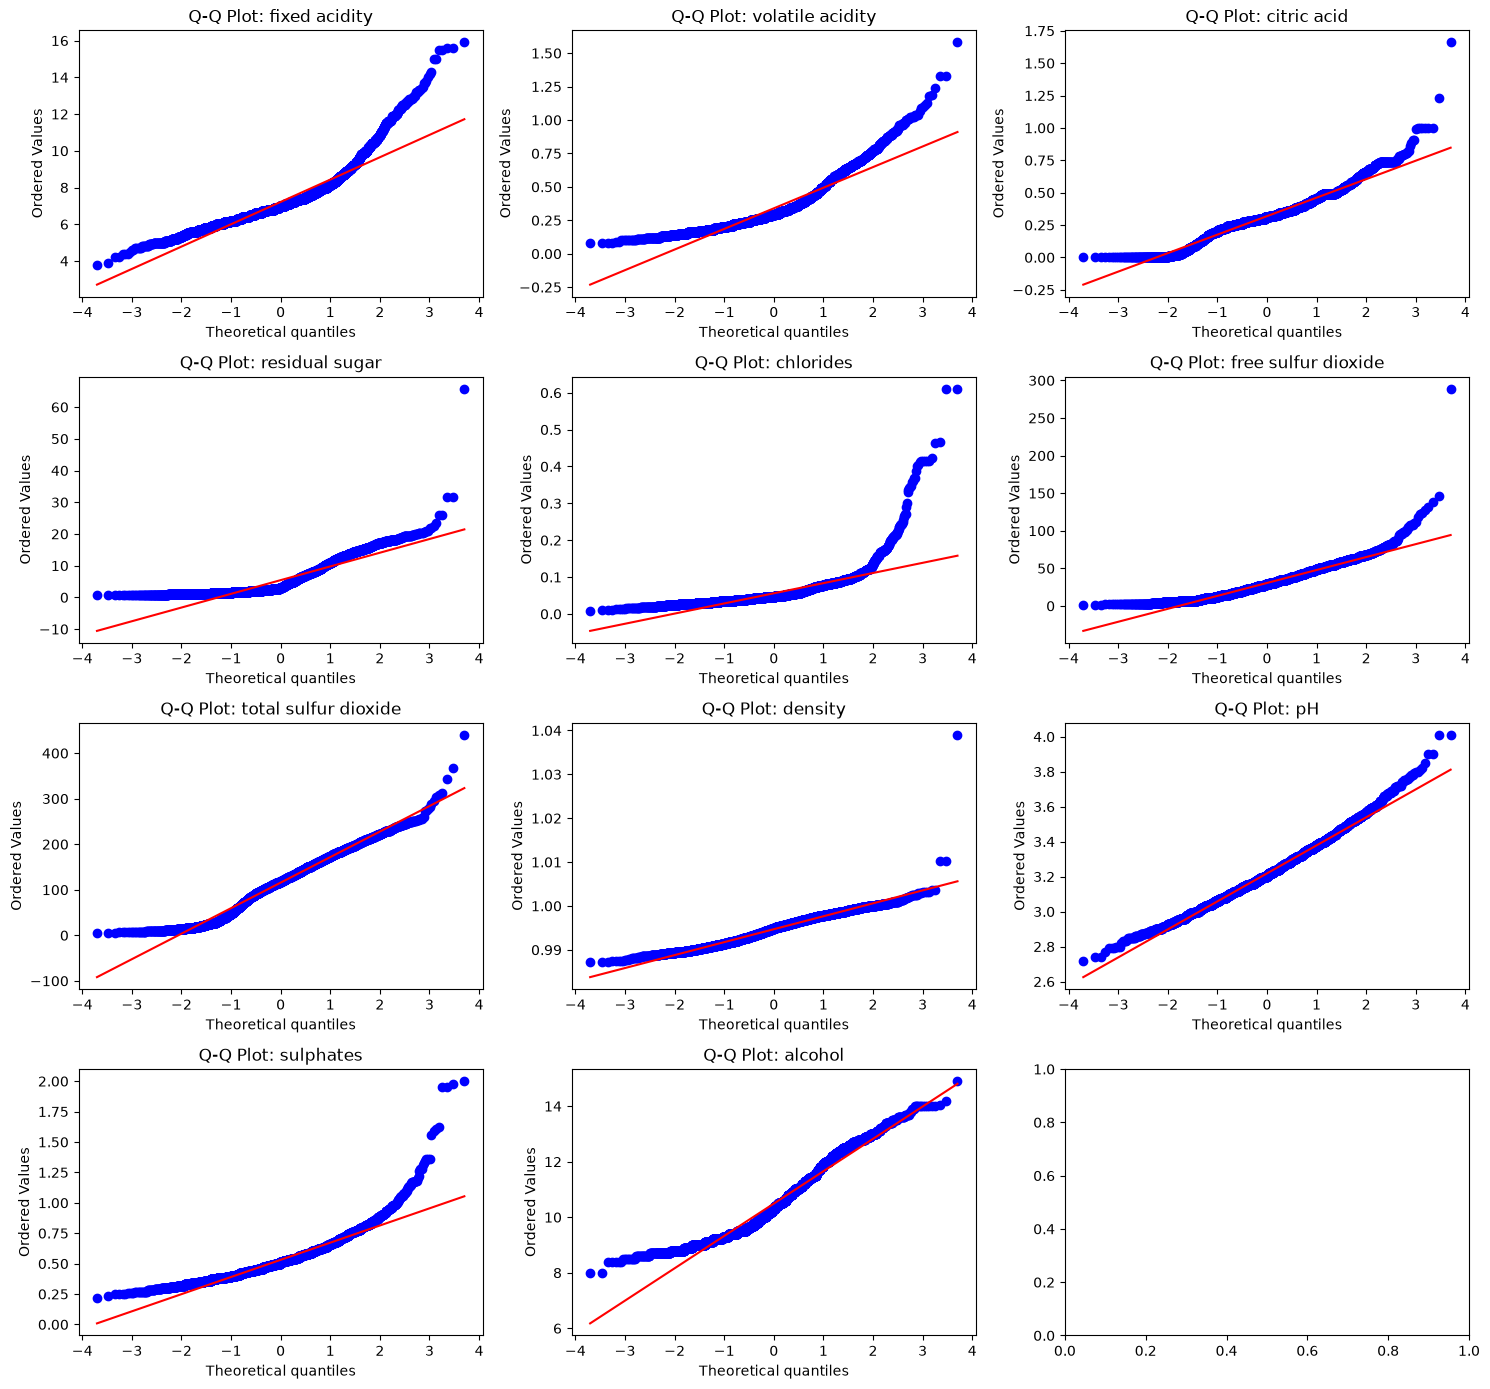

In [9]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    ax = axes[i]
    stats.probplot(df[col], dist='norm', plot=ax)
    ax.set_title(f'Q-Q Plot: {col}')
plt.tight_layout()
plt.show()

In [10]:
mean_values = df[features].mean()
median_values = df[features].median()
mode_values = df[features].mode().iloc[0]

central_tendency = pd.DataFrame({
    'Среднее': mean_values,
    'Медиана': median_values,
    'Мода': mode_values
})
display(central_tendency.round(3))

,Среднее,Медиана,Мода
fixed acidity,7.215,7.000,6.800
volatile acidity,0.340,0.290,0.280
citric acid,0.319,0.310,0.300
residual sugar,5.443,3.000,2.000
chlorides,0.056,0.047,0.044
free sulfur dioxide,30.525,29.000,29.000
total sulfur dioxide,115.745,118.000,111.000
density,0.995,0.995,0.997
pH,3.219,3.210,3.160
sulphates,0.531,0.510,0.500


In [11]:
variance = df[features].var(ddof=1)
std = df[features].std(ddof=1)
iqr = (df[features].quantile(0.75) - df[features].quantile(0.25))
mad = (df[features].sub(df[features].median()).abs().median())
data_range = df[features].max() - df[features].min()
cv = std / df[features].mean() * 100

dispersion = pd.DataFrame({
    'Дисперсия': variance,
    'Стандартное отклонение': std,
    'IQR': iqr,
    'MAD': mad,
    'Размах': data_range,
    'Коэффициент вариации, %': cv
})
display(dispersion.round(3))

,Дисперсия,Стандартное отклонение,IQR,MAD,Размах,"Коэффициент вариации, %"
fixed acidity,1.681,1.296,1.300,0.600,12.100,17.968
volatile acidity,0.027,0.165,0.170,0.080,1.500,48.470
citric acid,0.021,0.145,0.140,0.070,1.660,45.607
residual sugar,22.637,4.758,6.300,1.700,65.200,87.408
chlorides,0.001,0.035,0.027,0.011,0.602,62.522
free sulfur dioxide,315.041,17.749,24.000,12.000,288.000,58.146
total sulfur dioxide,3194.720,56.522,79.000,39.000,434.000,48.833
density,0.000,0.003,0.005,0.002,0.052,0.301
pH,0.026,0.161,0.210,0.110,1.290,4.996
sulphates,0.022,0.149,0.170,0.080,1.780,28.010


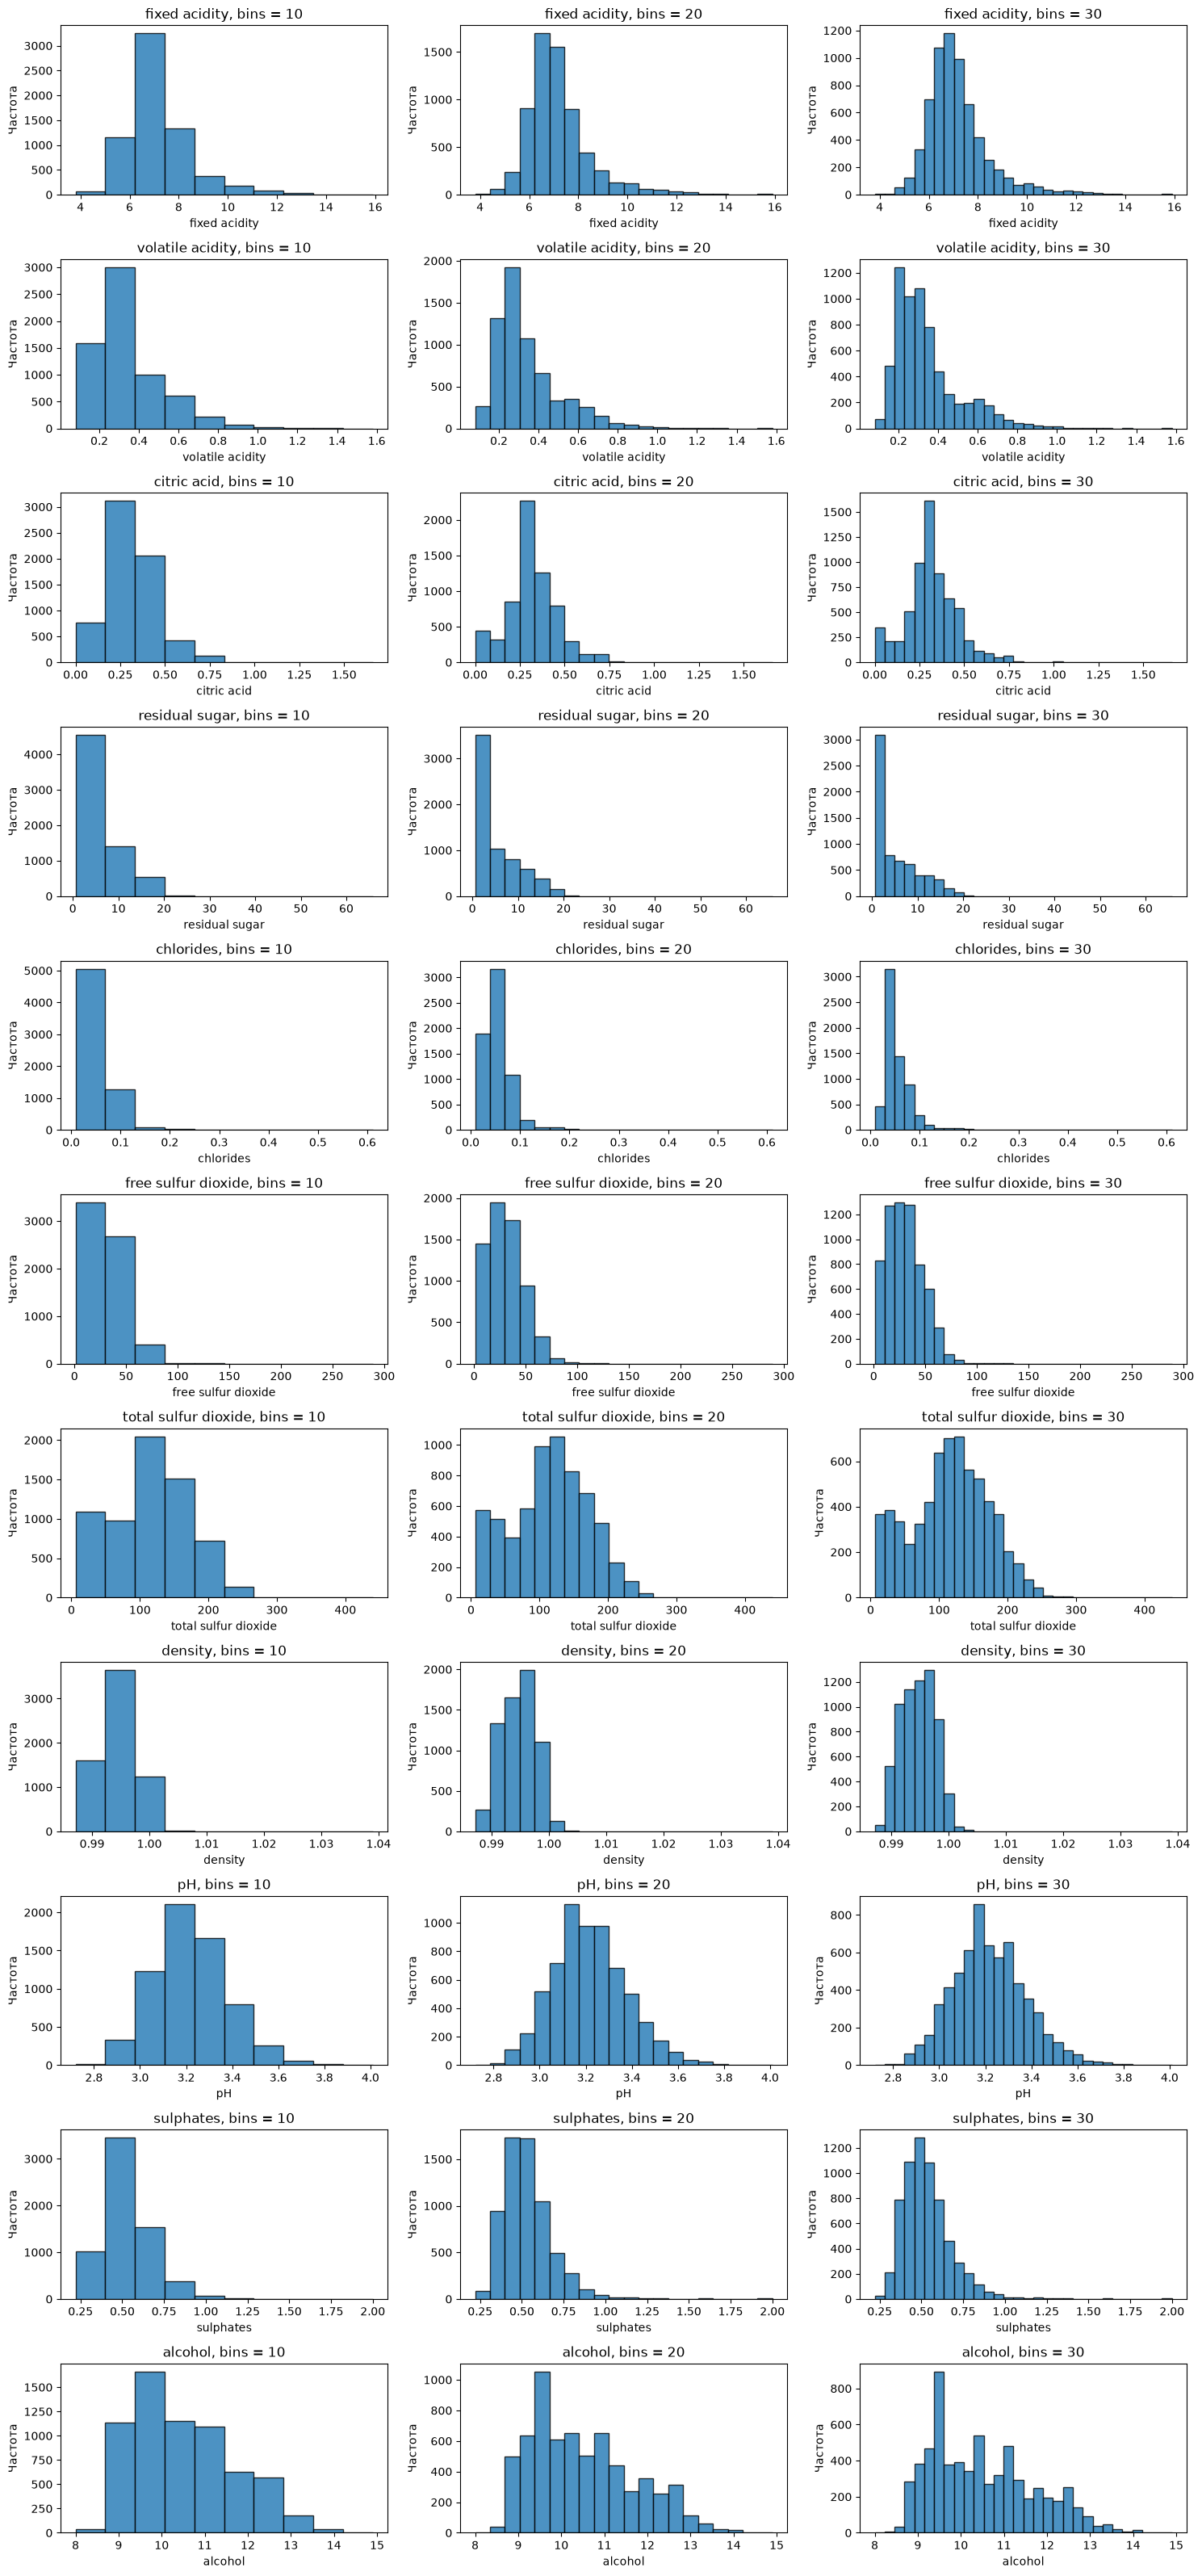

In [27]:
bins_list = [10, 20, 30]

fig, axes = plt.subplots(len(features), len(bins_list), figsize=(15, 32))

for i, col in enumerate(features):
    for j, b in enumerate(bins_list):
        ax = axes[i, j]
        ax.hist(df[col], bins=b, edgecolor='black', alpha=0.8)
        ax.set_title(f'{col}, bins = {b}')
        ax.set_xlabel(col)
        ax.set_ylabel('Частота')

plt.tight_layout()
plt.show()

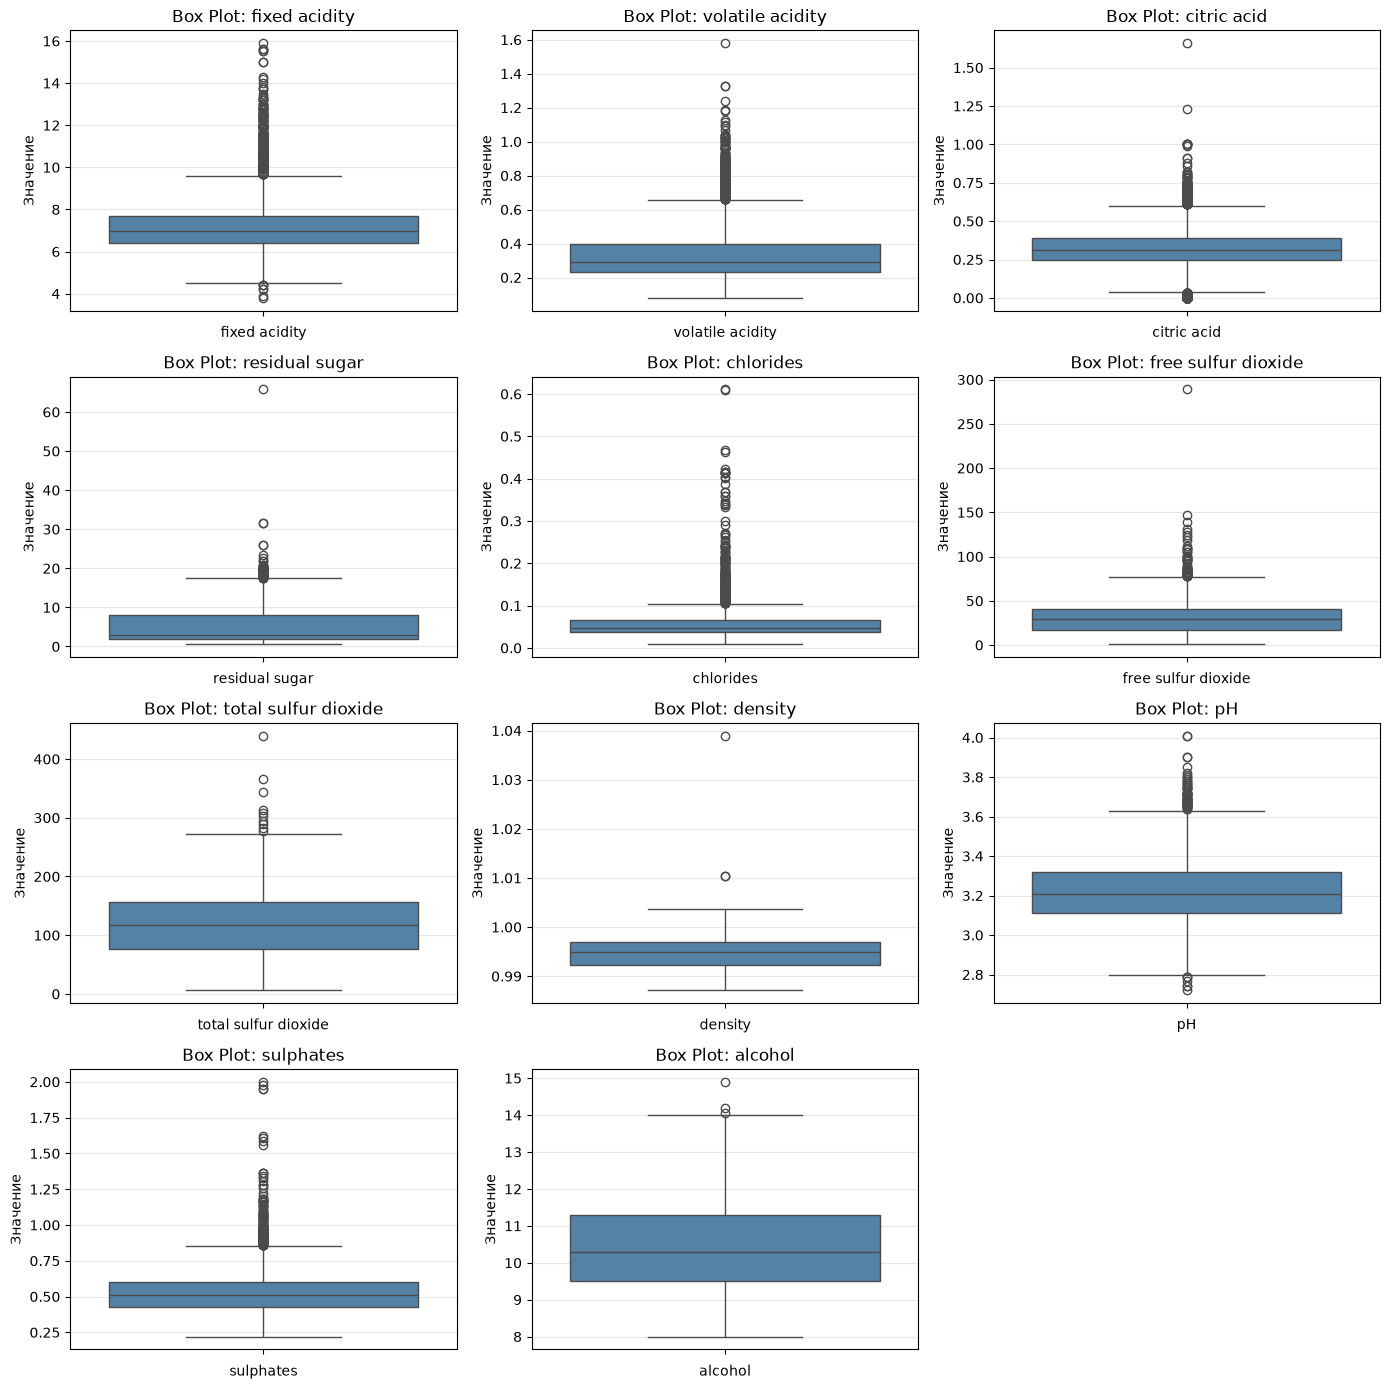

In [30]:
fig, axes = plt.subplots(4, 3, figsize=(14, 14))
axes = axes.flatten()

for i, col in enumerate(features):
    ax = axes[i]
    sns.boxplot(y=df[col], ax=ax, color='steelblue')
    ax.set_title(f'Box Plot: {col}')
    ax.set_ylabel('Значение')
    ax.set_xlabel(col)
    ax.grid(axis='y', alpha=0.3)

# если признаков меньше, чем ячеек — убираем пустые
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [26]:
Вoutliers = {}
outliers = {}
for feature in features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    mask = (df[feature] < lower_bound) | (df[feature] > upper_bound)
    outliers[feature] = df.loc[mask, feature]
    print(f'\nПризнак: {feature}')
    print(f'Q1 = {q1:.3f}')
    print(f'Q3 = {q3:.3f}')
    print(f'IQR = {iqr:.3f}')
    print(f'Нижняя граница = {lower_bound:.3f}')
    print(f'Верхняя граница = {upper_bound:.3f}')
    print(f'Количество выбросов: {mask.sum()}')


Признак: fixed acidity
Q1 = 6.400
Q3 = 7.700
IQR = 1.300
Нижняя граница = 4.450
Верхняя граница = 9.650
Количество выбросов: 357

Признак: volatile acidity
Q1 = 0.230
Q3 = 0.400
IQR = 0.170
Нижняя граница = -0.025
Верхняя граница = 0.655
Количество выбросов: 377

Признак: citric acid
Q1 = 0.250
Q3 = 0.390
IQR = 0.140
Нижняя граница = 0.040
Верхняя граница = 0.600
Количество выбросов: 509

Признак: residual sugar
Q1 = 1.800
Q3 = 8.100
IQR = 6.300
Нижняя граница = -7.650
Верхняя граница = 17.550
Количество выбросов: 118

Признак: chlorides
Q1 = 0.038
Q3 = 0.065
IQR = 0.027
Нижняя граница = -0.003
Верхняя граница = 0.106
Количество выбросов: 286

Признак: free sulfur dioxide
Q1 = 17.000
Q3 = 41.000
IQR = 24.000
Нижняя граница = -19.000
Верхняя граница = 77.000
Количество выбросов: 62

Признак: total sulfur dioxide
Q1 = 77.000
Q3 = 156.000
IQR = 79.000
Нижняя граница = -41.500
Верхняя граница = 274.500
Количество выбросов: 10

Признак: density
Q1 = 0.992
Q3 = 0.997
IQR = 0.005
Нижняя гран

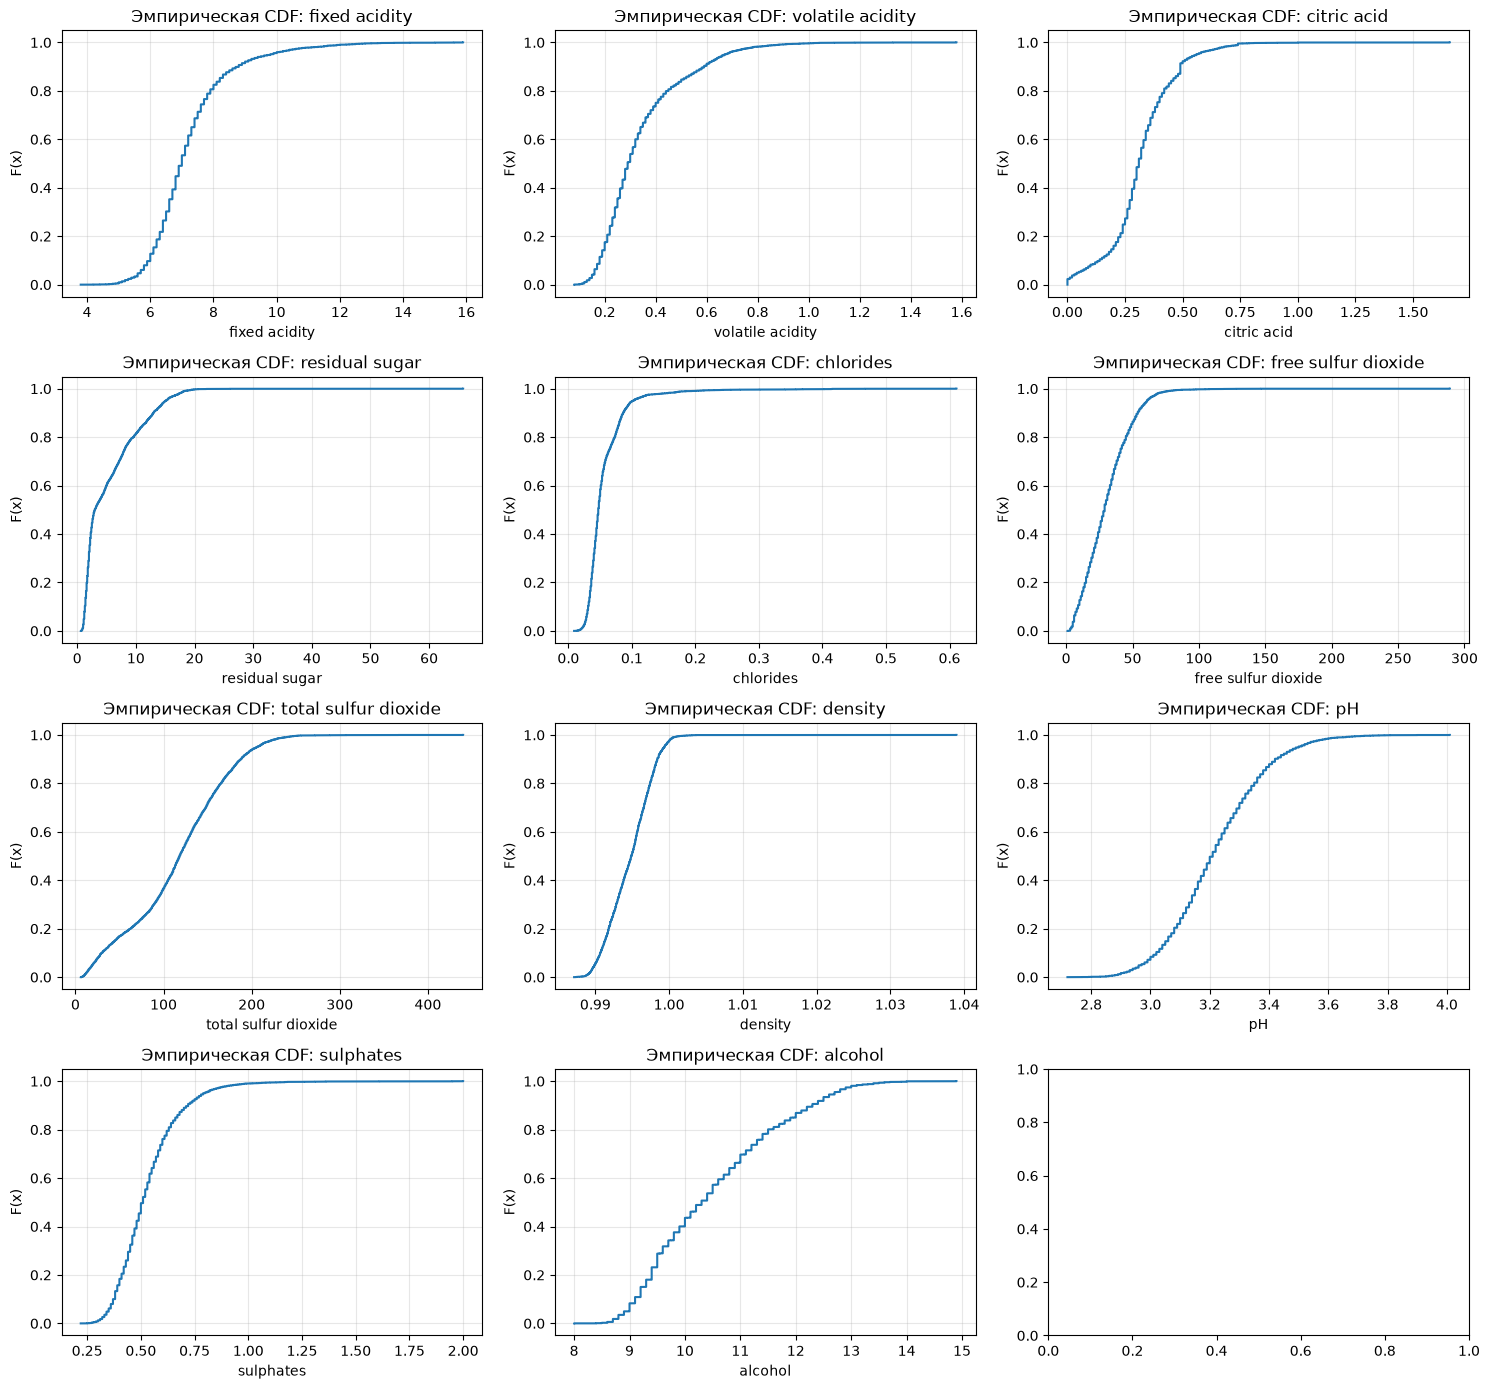

In [15]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()
for i, col in enumerate(features):
    ax = axes[i]
    sorted_data = np.sort(df[col])
    yvals = np.arange(len(sorted_data)) / float(len(sorted_data) - 1)
    ax.step(sorted_data, yvals, where='post')
    ax.set_title(f'Эмпирическая CDF: {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('F(x)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
percentiles = [10, 25, 50, 75, 90]
percentile_table = df[features].quantile(np.array(percentiles) / 100)
percentile_table.index = [f'{p}-й процентиль' for p in percentiles]
display(percentile_table.round(3))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
10-й процентиль,6.0,0.18,0.14,1.3,0.031,9.0,30.0,0.991,3.02,0.37,9.1
25-й процентиль,6.4,0.23,0.25,1.8,0.038,17.0,77.0,0.992,3.11,0.43,9.5
50-й процентиль,7.0,0.29,0.31,3.0,0.047,29.0,118.0,0.995,3.21,0.51,10.3
75-й процентиль,7.7,0.40,0.39,8.1,0.065,41.0,156.0,0.997,3.32,0.60,11.3
90-й процентиль,8.8,0.59,0.49,13.0,0.086,54.0,188.0,0.998,3.42,0.72,12.3


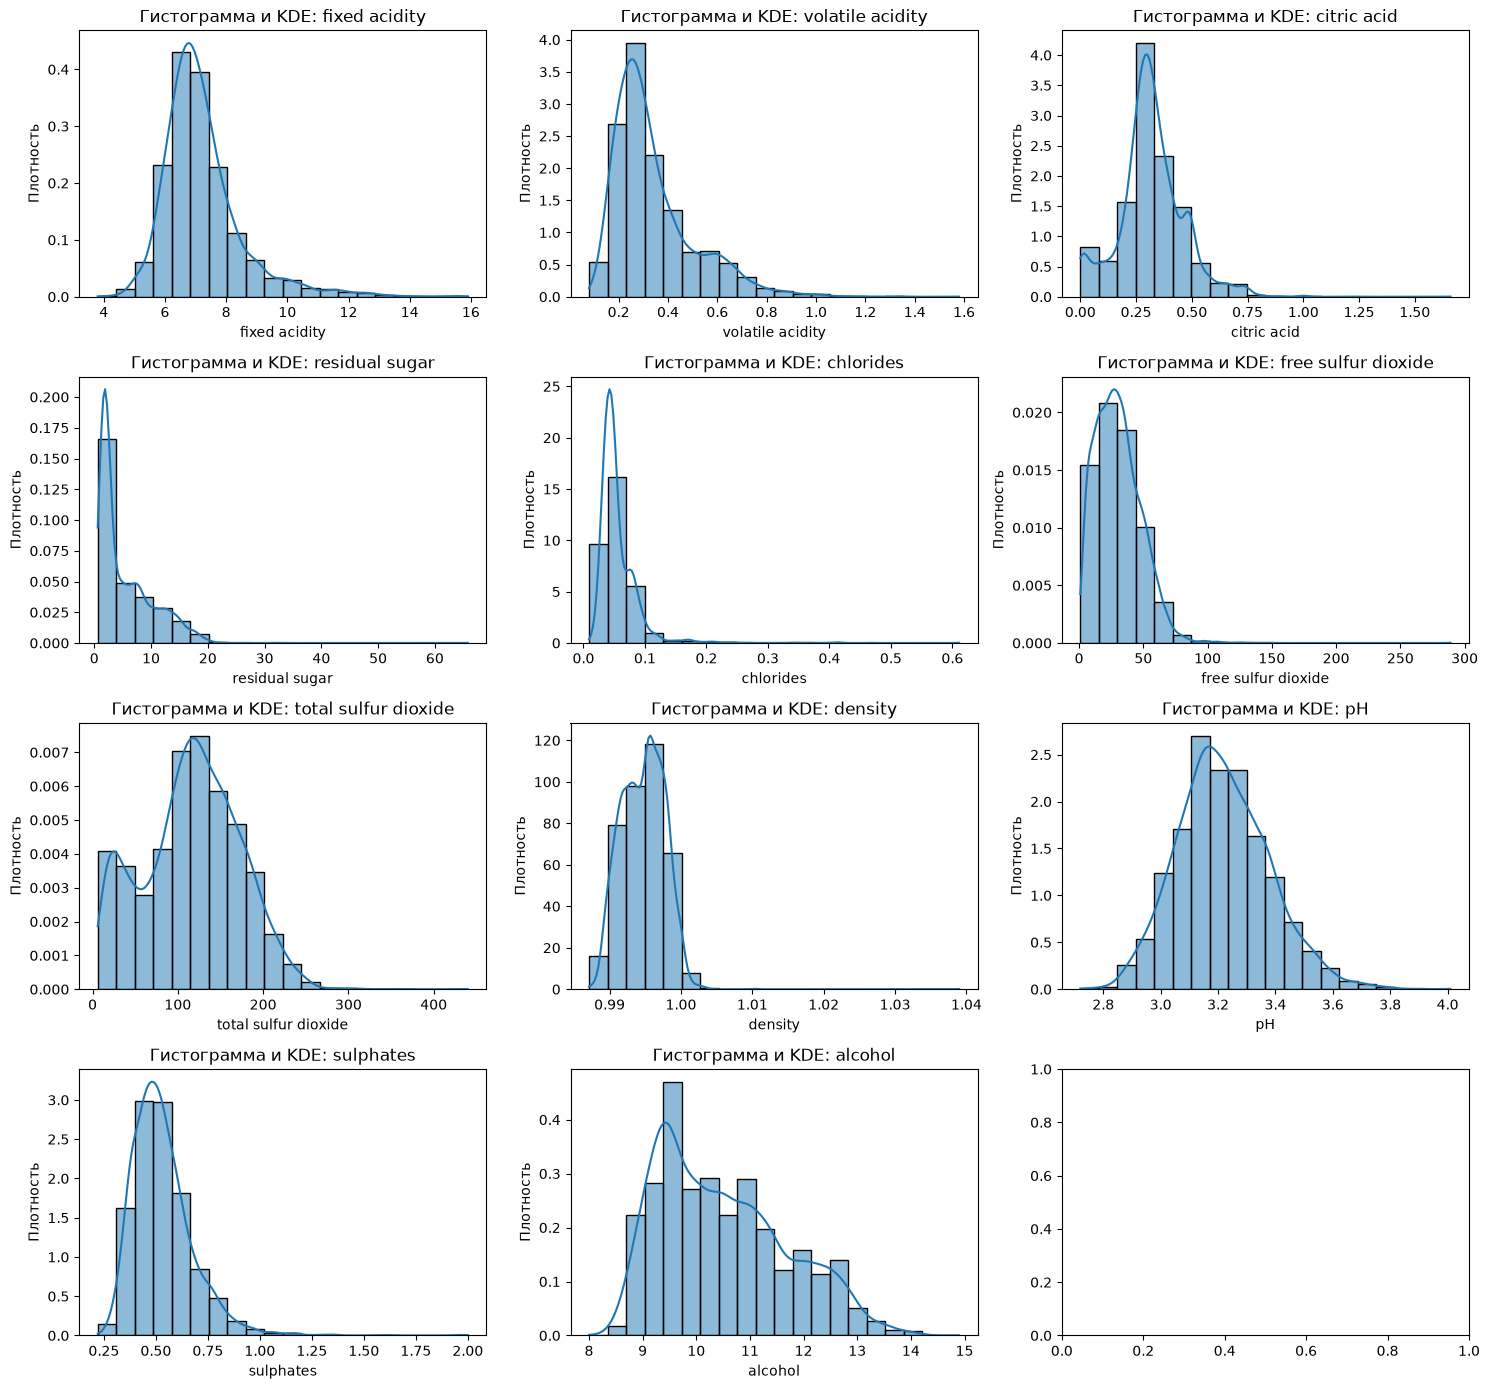

In [17]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()
for i, feature in enumerate(features):
    ax = axes[i]
    sns.histplot(data=df, x=feature, bins=20, stat='density', kde=True, ax=ax)
    ax.set_title(f'Гистограмма и KDE: {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Плотность')
plt.tight_layout()
plt.show()

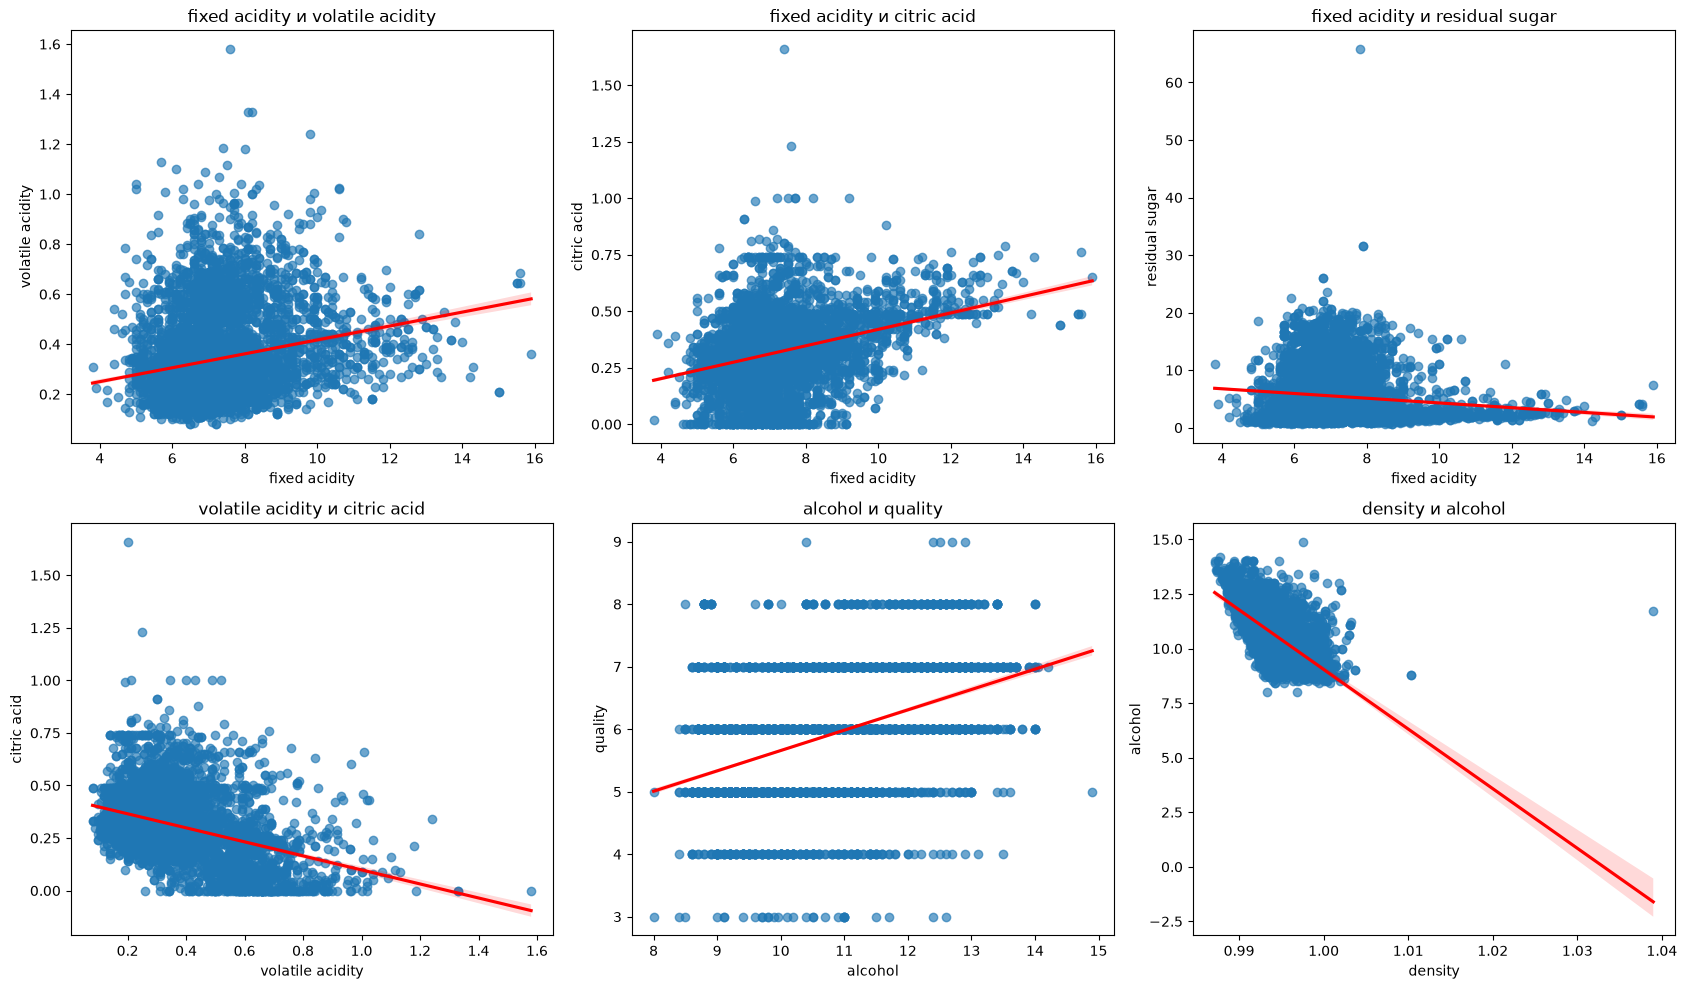

In [18]:
pairs = [
    ('fixed acidity', 'volatile acidity'),
    ('fixed acidity', 'citric acid'),
    ('fixed acidity', 'residual sugar'),
    ('volatile acidity', 'citric acid'),
    ('alcohol', 'quality'),
    ('density', 'alcohol')
]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (x, y) in zip(axes.flat, pairs):
    sns.regplot(data=df, x=x, y=y, ax=ax, scatter_kws={'alpha': 0.65}, line_kws={'color': 'red'})
    ax.set_title(f'{x} и {y}')
plt.tight_layout()
plt.show()

In [19]:
covariance_matrix = df[features].cov()
display(covariance_matrix.round(3))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.681,0.047,0.061,-0.691,0.014,-6.506,-24.112,0.002,-0.053,0.058,-0.148
volatile acidity,0.047,0.027,-0.009,-0.154,0.002,-1.030,-3.857,0.000,0.007,0.006,-0.007
citric acid,0.061,-0.009,0.021,0.098,0.000,0.343,1.604,0.000,-0.008,0.001,-0.002
residual sugar,-0.691,-0.154,0.098,22.637,-0.021,34.022,133.245,0.008,-0.204,-0.132,-2.040
chlorides,0.014,0.002,0.000,-0.021,0.001,-0.121,-0.554,0.000,0.000,0.002,-0.011
free sulfur dioxide,-6.506,-1.030,0.343,34.022,-0.121,315.041,723.262,0.001,-0.416,-0.498,-3.807
total sulfur dioxide,-24.112,-3.857,1.604,133.245,-0.554,723.262,3194.720,0.005,-2.167,-2.319,-17.915
density,0.002,0.000,0.000,0.008,0.000,0.001,0.005,0.000,0.000,0.000,-0.002
pH,-0.053,0.007,-0.008,-0.204,0.000,-0.416,-2.167,0.000,0.026,0.005,0.023
sulphates,0.058,0.006,0.001,-0.132,0.002,-0.498,-2.319,0.000,0.005,0.022,-0.001


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.000,0.219,0.324,-0.112,0.298,-0.283,-0.329,0.459,-0.253,0.300,-0.095
volatile acidity,0.219,1.000,-0.378,-0.196,0.377,-0.353,-0.414,0.271,0.261,0.226,-0.038
citric acid,0.324,-0.378,1.000,0.142,0.039,0.133,0.195,0.096,-0.330,0.056,-0.010
residual sugar,-0.112,-0.196,0.142,1.000,-0.129,0.403,0.495,0.553,-0.267,-0.186,-0.359
chlorides,0.298,0.377,0.039,-0.129,1.000,-0.195,-0.280,0.363,0.045,0.396,-0.257
free sulfur dioxide,-0.283,-0.353,0.133,0.403,-0.195,1.000,0.721,0.026,-0.146,-0.188,-0.180
total sulfur dioxide,-0.329,-0.414,0.195,0.495,-0.280,0.721,1.000,0.032,-0.238,-0.276,-0.266
density,0.459,0.271,0.096,0.553,0.363,0.026,0.032,1.000,0.012,0.259,-0.687
pH,-0.253,0.261,-0.330,-0.267,0.045,-0.146,-0.238,0.012,1.000,0.192,0.121
sulphates,0.300,0.226,0.056,-0.186,0.396,-0.188,-0.276,0.259,0.192,1.000,-0.003


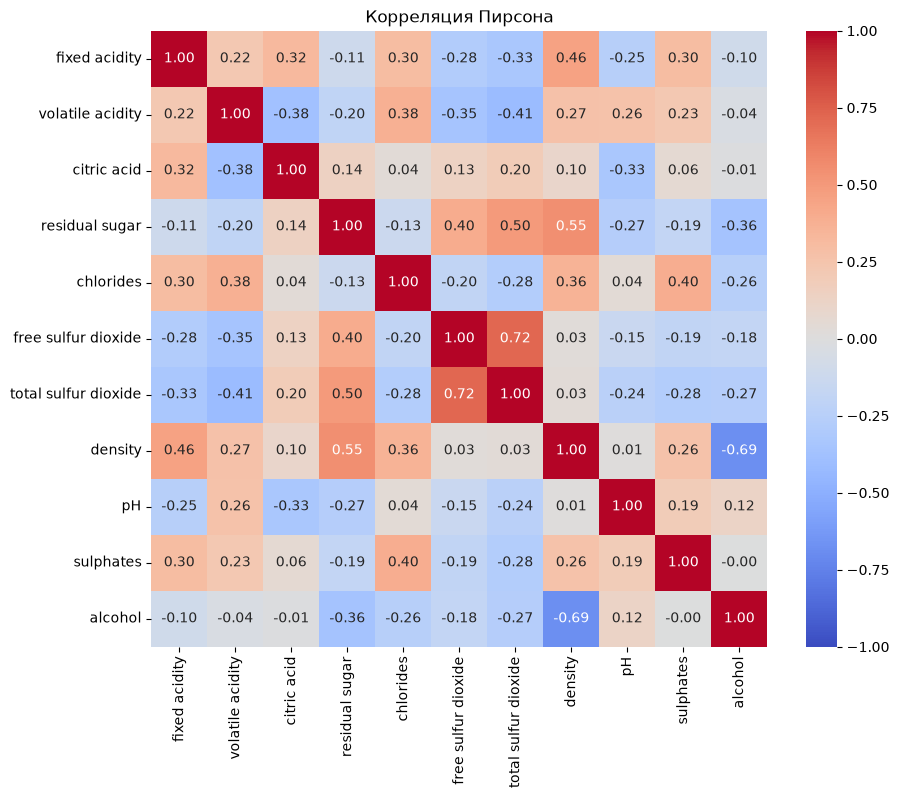

In [20]:
pearson_matrix = df[features].corr(method='pearson')
display(pearson_matrix.round(3))

plt.figure(figsize=(10, 8))
sns.heatmap(pearson_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Корреляция Пирсона')
plt.show()

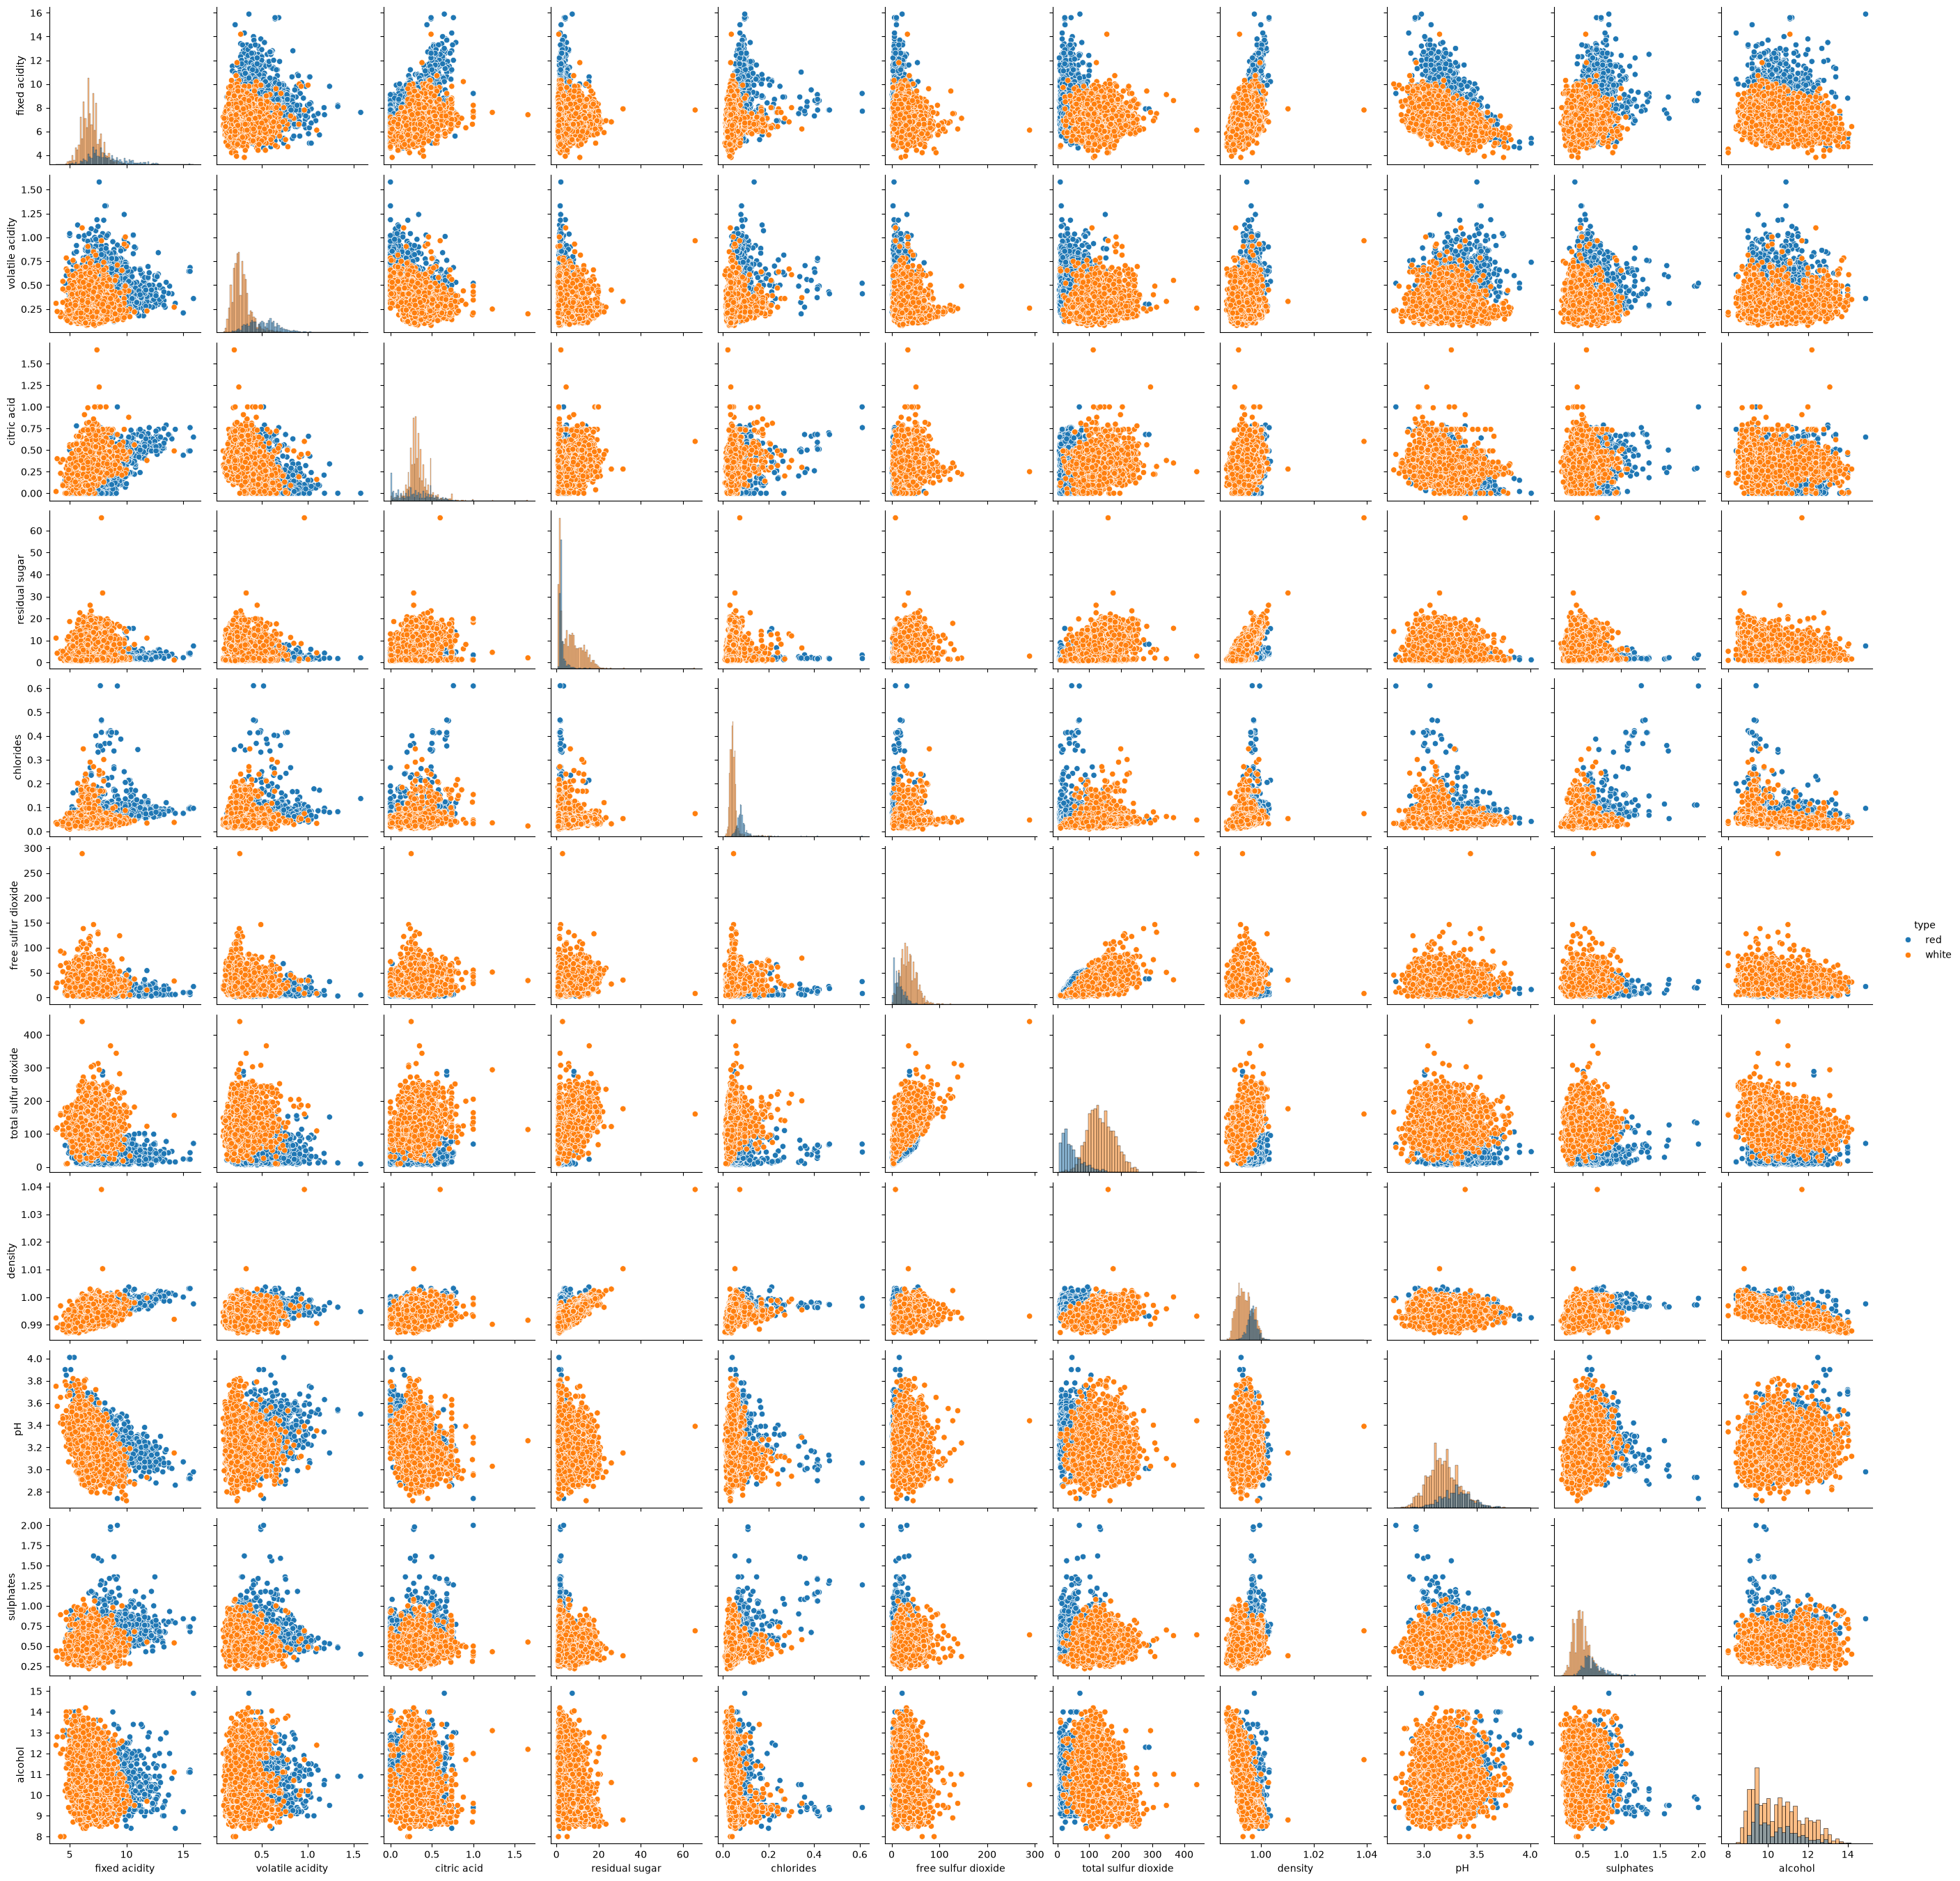

In [21]:
sns.pairplot(df, vars=features, hue='type', diag_kind='hist')
plt.show()

In [22]:
outlier_mask = pd.Series(False, index=df.index)
for feature in features:
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    feature_outliers = (df[feature] < lower_bound) | (df[feature] > upper_bound)
    outlier_mask = outlier_mask | feature_outliers

print('Количество наблюдений с потенциальными выбросами:', outlier_mask.sum())

corr_all = df[features].corr()
corr_without_outliers = df.loc[~outlier_mask, features].corr()

print('Корреляция для всей выборки:')
display(corr_all.round(3))
print('Корреляция без выбросов:')
display(corr_without_outliers.round(3))

Количество наблюдений с потенциальными выбросами: 1473
Корреляция для всей выборки:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.000,0.219,0.324,-0.112,0.298,-0.283,-0.329,0.459,-0.253,0.300,-0.095
volatile acidity,0.219,1.000,-0.378,-0.196,0.377,-0.353,-0.414,0.271,0.261,0.226,-0.038
citric acid,0.324,-0.378,1.000,0.142,0.039,0.133,0.195,0.096,-0.330,0.056,-0.010
residual sugar,-0.112,-0.196,0.142,1.000,-0.129,0.403,0.495,0.553,-0.267,-0.186,-0.359
chlorides,0.298,0.377,0.039,-0.129,1.000,-0.195,-0.280,0.363,0.045,0.396,-0.257
free sulfur dioxide,-0.283,-0.353,0.133,0.403,-0.195,1.000,0.721,0.026,-0.146,-0.188,-0.180
total sulfur dioxide,-0.329,-0.414,0.195,0.495,-0.280,0.721,1.000,0.032,-0.238,-0.276,-0.266
density,0.459,0.271,0.096,0.553,0.363,0.026,0.032,1.000,0.012,0.259,-0.687
pH,-0.253,0.261,-0.330,-0.267,0.045,-0.146,-0.238,0.012,1.000,0.192,0.121
sulphates,0.300,0.226,0.056,-0.186,0.396,-0.188,-0.276,0.259,0.192,1.000,-0.003


Корреляция без выбросов:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
fixed acidity,1.000,0.151,0.238,-0.033,0.318,-0.173,-0.152,0.347,-0.250,0.134,-0.113
volatile acidity,0.151,1.000,-0.321,-0.115,0.428,-0.282,-0.265,0.185,0.182,0.173,-0.010
citric acid,0.238,-0.321,1.000,0.096,-0.118,0.139,0.170,0.031,-0.176,0.021,0.042
residual sugar,-0.033,-0.115,0.096,1.000,-0.049,0.417,0.475,0.652,-0.245,-0.127,-0.396
chlorides,0.318,0.428,-0.118,-0.049,1.000,-0.188,-0.235,0.524,0.204,0.308,-0.395
free sulfur dioxide,-0.173,-0.282,0.139,0.417,-0.188,1.000,0.680,0.169,-0.125,-0.100,-0.202
total sulfur dioxide,-0.152,-0.265,0.170,0.475,-0.235,0.680,1.000,0.231,-0.192,-0.160,-0.328
density,0.347,0.185,0.031,0.652,0.524,0.169,0.231,1.000,0.054,0.200,-0.776
pH,-0.250,0.182,-0.176,-0.245,0.204,-0.125,-0.192,0.054,1.000,0.278,0.057
sulphates,0.134,0.173,0.021,-0.127,0.308,-0.100,-0.160,0.200,0.278,1.000,-0.033


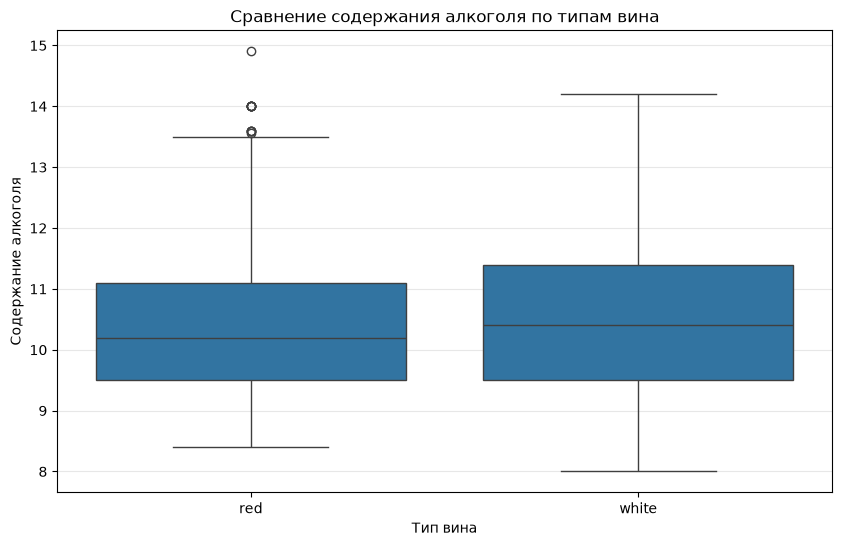

In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='type', y='alcohol')
plt.title('Сравнение содержания алкоголя по типам вина')
plt.xlabel('Тип вина')
plt.ylabel('Содержание алкоголя')
plt.grid(axis='y', alpha=0.3)
plt.show()

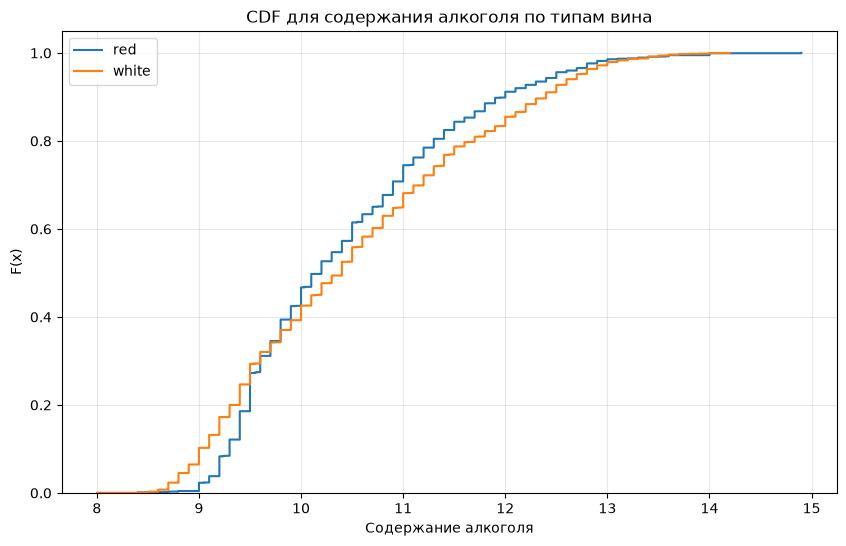

In [24]:
plt.figure(figsize=(10, 6))
for wine_type in df['type'].unique():
    values = np.sort(df.loc[df['type'] == wine_type, 'alcohol'])
    probabilities = np.arange(1, len(values) + 1) / len(values)
    plt.step(values, probabilities, where='post', label=wine_type)
plt.title('CDF для содержания алкоголя по типам вина')
plt.xlabel('Содержание алкоголя')
plt.ylabel('F(x)')
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [25]:
group_statistics = df.groupby('type')['alcohol'].agg(
    Среднее='mean',
    Медиана='median',
    Стандартное_отклонение='std',
    Минимум='min',
    Максимум='max',
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)
group_statistics['IQR'] = group_statistics['Q3'] - group_statistics['Q1']
display(group_statistics.round(3))

,Среднее,Медиана,Стандартное_отклонение,Минимум,Максимум,Q1,Q3,IQR
type,,,,,,,,
red,10.423,10.2,1.066,8.4,14.9,9.5,11.1,1.6
white,10.514,10.4,1.231,8.0,14.2,9.5,11.4,1.9
